# Datenstrukturen: Python-Listen (Musterlösung) {#sec-loesung-listen}

Bisher hat jede Variable auf genau einen Wert verwiesen: eine Zahl,
einen String oder eine Grafik. Mit der Python-Liste lernen wir in diesem
Kapitel eine erste Datenstruktur kennen. Eine Datenstruktur fasst mehrere
Werte nach einem bestimmten Ordnungsprinzip zusammen, bei der Liste in einer
festen Reihenfolge, und ermöglicht es, diese Werte gezielt anzusprechen und
zu bearbeiten.

Bearbeitet werden Listen einerseits mit eingebauten Funktionen wie `len()`
und mit Operatoren wie `[]`, andererseits mit sogenannten *Methoden*.
Methoden sind Funktionen, die zu einem bestimmten Datentyp gehören und mit
einem Punkt direkt auf einem Wert aufgerufen werden, z. B.
`einkaufsliste.append('Brot')`. Im Unterschied zu den bisher verwendeten
Funktionen verändern viele Listenmethoden die Liste direkt, statt ein neues
Resultat zurückzugeben.

Das Kapitel führt in drei Etappen von den Grundlagen zu einem grösseren
Projekt. Zuerst lernen wir, wie Listen angelegt, gefüllt, durchlaufen und
ausgewertet werden. Danach sehen wir, dass eine Animation nichts anderes ist
als eine Liste von Grafiken. Mit diesem Wissen bauen wir schliesslich zwei
Animationen mit PyTamaro: einen PacMan, der den Mund auf- und zuklappt, und
als Abschlussübung die Bahnhofsuhr der SBB.

Zunächst aber ein Blick darauf, wie eine Liste im Arbeitsspeicher aufgebaut
ist.

::: {.callout-note title="INFO Python-Listen sind dynamische Arrays"}

**Was ist ein Array?**

Ein Array ist eine der grundlegendsten Datenstrukturen der Informatik. Man
kann es sich wie eine Reihe von nummerierten Schliessfächern vorstellen, die
lückenlos nebeneinander im Arbeitsspeicher liegen. Alle Fächer sind gleich
gross, und jedes hat eine Nummer, den sogenannten *Index*.

Weil die Fächer lückenlos aneinandergereiht und gleich gross sind, kann der
Computer die Position jedes Fachs direkt berechnen:

Position = Anfang des Arrays + Index · Grösse eines Fachs

Der Computer muss also nicht alle Fächer der Reihe nach durchsuchen, um das
gewünschte zu finden. Der Zugriff auf das tausendste Element dauert gleich
lang wie der Zugriff auf das erste. Diese Berechnung erklärt übrigens auch,
weshalb in Python mit 0 zu zählen begonnen wird: Der Index gibt an, wie viele
Fächer vom Anfang aus übersprungen werden. Das erste Element liegt direkt am
Anfang, also bei Index 0.

**Das Problem: Ein Array hat eine feste Grösse**

Ein klassisches Array wird mit einer festen Anzahl Fächer angelegt. Ist es
voll, kann es nicht einfach verlängert werden, denn der Speicherplatz direkt
dahinter ist möglicherweise bereits anderweitig belegt.

**Die Lösung: Das dynamische Array**

Python löst dieses Problem mit einem Trick. Beim Anlegen einer Liste
reserviert Python etwas mehr Fächer, als im Moment gebraucht werden. Neue
Elemente können so am Ende einfach in ein freies Fach gelegt werden. Erst wenn
alle reservierten Fächer belegt sind, sucht Python einen neuen, grösseren
Speicherbereich, kopiert alle bisherigen Elemente dorthin und gibt den alten
Bereich frei. Für uns geschieht das unsichtbar: Die Liste scheint einfach
beliebig wachsen zu können. Deshalb spricht man von einem *dynamischen* Array.

**Was das für die Praxis bedeutet**

- Der Zugriff über den Index (`liste[5]`) ist immer schnell, egal wie lang die
  Liste ist.
- Das Anhängen am Ende (`liste.append(x)`) ist in aller Regel schnell.
- Das Einfügen oder Entfernen am Anfang oder in der Mitte einer Liste ist
  dagegen aufwendig: Alle nachfolgenden Elemente müssen um ein Fach verschoben
  werden. Bei langen Listen kann das spürbar Zeit kosten.

Warum dieser Unterschied wichtig ist, wird beim Thema *Beurteilung von
Algorithmen* noch genauer betrachtet.

:::

::: {.callout-tip collapse="true"}
## Vertiefung: Warum kann eine Liste Werte unterschiedlicher Typen enthalten?

Eine Zahl braucht weniger Speicherplatz als ein langer Text. Wie passt das
zu gleich grossen Fächern? In den Fächern einer Python-Liste liegen nicht die
Werte selbst, sondern Verweise auf die Orte im Arbeitsspeicher, an denen die
Werte abgelegt sind, genau wie bei Variablen. Alle Verweise sind gleich gross,
unabhängig davon, worauf sie zeigen. Deshalb kann eine Liste problemlos Zahlen,
Strings und sogar PyTamaro-Grafiken gleichzeitig enthalten.

:::

## Elemente hinzufügen: Die Methode `.append()`

Eine Liste wird mit eckigen Klammern angelegt. Die einzelnen Elemente werden
durch Kommas getrennt.


In [1]:
einkaufsliste = ['Brot', 'Milch']
einkaufsliste

['Brot', 'Milch']


Häufig steht beim Anlegen einer Liste noch nicht fest, welche Elemente sie
später enthalten soll. Eine Liste kann deshalb auch leer angelegt und
anschliessend schrittweise gefüllt werden. Dafür stellt Python die Methode
`.append()` zur Verfügung. Sie hängt das als Argument übergebene Element am
Ende der Liste an.


In [2]:

einkaufsliste.append('Käse')
einkaufsliste


['Brot', 'Milch', 'Käse']

Beachten Sie die Schreibweise: Die Methode wird mit einem Punkt direkt an den
Namen der Liste angehängt. Damit ist klar, *welche* Liste verändert werden
soll.

::: {.callout-warning title="Achtung: `.append()` verändert die Liste direkt"}

Bei PyTamaro haben Sie sich daran gewöhnt, das Resultat einer Funktion einer
Variablen zuzuweisen:

```python
blume = kombiniere(blume, bluetenblatt_gedreht)
```

`kombiniere()` verändert die bestehende Grafik nicht, sondern erstellt eine
neue. Diese muss deshalb in einer Variablen gespeichert werden.

`.append()` funktioniert anders: Die Methode verändert die bestehende Liste
direkt und gibt kein Resultat zurück, genauer gesagt den speziellen Wert
`None` (engl. für *nichts*). Wer das Muster von PyTamaro überträgt, verliert
seine Liste. Das folgende Beispiel verwendet dafür eine eigene Liste, damit
die Einkaufsliste für die weiteren Beispiele erhalten bleibt:

In [3]:
vorraete = ['Reis', 'Mehl']
vorraete = vorraete.append('Zucker')  # FALSCH!
print(vorraete)

None


Die Variable `vorraete` verweist jetzt nicht mehr auf die Liste, sondern auf
`None`. Richtig ist deshalb immer:

```python
vorraete.append('Zucker')  # richtig: ohne Zuweisung
```

:::

Besonders nützlich wird `.append()` in Kombination mit einer For-Schleife. Im
folgenden Beispiel wird eine leere Liste angelegt und in jedem
Schleifendurchlauf um eine Quadratzahl ergänzt.

In [4]:

quadratzahlen = []

for zahl in range(1, 6):
    quadratzahlen.append(zahl ** 2)

quadratzahlen


[1, 4, 9, 16, 25]

In [5]:
# TODO: Legen Sie eine leere Liste an und füllen Sie sie mit einer
# For-Schleife mit allen Vielfachen von 7 zwischen 7 und 70.
vielfache = []

for zahl in range(7, 71, 7):
    vielfache.append(zahl)

vielfache

[7, 14, 21, 28, 35, 42, 49, 56, 63, 70]


## Über Listen iterieren

Bisher haben wir For-Schleifen ausschliesslich mit `range()` verwendet. Eine
For-Schleife kann aber auch über eine Liste laufen. Die Schleifenvariable nimmt
dabei in jedem Durchlauf der Reihe nach den Wert des nächsten Elements an.
Man sagt, die Schleife *iteriert* über die Liste.


In [6]:

for artikel in einkaufsliste:
    print(artikel)


Brot
Milch
Käse



Das ist kein Sonderfall: Auch `range(5)` liefert der Schleife einfach der
Reihe nach die Werte 0, 1, 2, 3 und 4. Eine Liste liefert stattdessen ihre
Elemente. Man spricht daher von einem *iterable*.

### Namenskonventionen

Python ist es gleichgültig, wie die Schleifenvariable heisst. Für Menschen,
die den Code lesen, macht der Name dagegen einen grossen Unterschied. Es haben
sich deshalb die folgenden Konventionen eingebürgert:

- **Listen erhalten einen Namen im Plural**, weil sie mehrere Elemente
  enthalten: `farben`, `zahlen`, `namen`. Alternativ kann ein Sammelbegriff
  verwendet werden, wie bei `einkaufsliste`.
- **Die Schleifenvariable erhält den passenden Namen im Singular**, weil sie
  in jedem Durchlauf genau *ein* Element bezeichnet: `for farbe in farben`,
  `for zahl in zahlen`, `for name in namen`.
- **Einbuchstabige Namen wie `i` werden nur für Zähler verwendet**, also wenn
  die Schleife mit `range()` über Zahlen läuft, die eine Position oder eine
  Anzahl Wiederholungen bezeichnen. Diese Konvention stammt aus der
  Mathematik, wo `i` traditionell für einen Index steht.

Vergleichen Sie die beiden folgenden Schleifen. Sie tun genau dasselbe, aber
nur bei der zweiten ist auf den ersten Blick klar, was passiert.

```python
for i in x:
    print(i)

for artikel in einkaufsliste:
    print(artikel)
```

Gut gewählte Namen machen den Code fast zu einem lesbaren Satz: *Für jeden
Artikel in der Einkaufsliste: gib den Artikel aus.*

## Listen erzeugen mit `list()` und mit Listen rechnen

### Die Funktion `list()`

Im Abschnitt über For-Schleifen haben wir gesehen, dass `range()` der Schleife
der Reihe nach Zahlen liefert. Eine Liste ist das Ergebnis von `range()`
allerdings nicht:


In [7]:
range(5)



range(0, 5)


Python zeigt nicht die Zahlen 0 bis 4 an, sondern nur `range(0, 5)`. Ein
`range` erzeugt die Zahlen erst dann, wenn sie gebraucht werden, zum Beispiel
in einer For-Schleife. Das spart Speicherplatz, bedeutet aber auch: Mit einem
`range` lassen sich viele Listenoperationen nicht durchführen.

Die Funktion `list()` löst dieses Problem. Sie nimmt als Argument eine Folge
von Werten entgegen und erzeugt daraus eine Liste:


In [8]:


list(range(5))



[0, 1, 2, 3, 4]

In [9]:

list(range(60, 55, -1))



[60, 59, 58, 57, 56]


`list()` funktioniert nicht nur mit `range`, sondern mit allem, über das eine
For-Schleife laufen kann. Ein String ist zum Beispiel eine Folge von Zeichen:


In [10]:

list('Hallo')


['H', 'a', 'l', 'l', 'o']


Ohne Argument erzeugt `list()` eine leere Liste. `list()` und `[]` bedeuten
also dasselbe.

### Operationen mit Listen

Für Listen stellt Python verschiedene Operatoren und eingebaute Funktionen
zur Verfügung. Die folgenden Beispiele verwenden diese Liste:


In [11]:

zahlen = [3, 1, 4, 1, 5]




**Zugriff über den Index**

Mit eckigen Klammern wird ein einzelnes Element angesprochen. Wie in der
INFO-Box zu den Arrays erklärt, beginnt die Zählung bei 0. Negative Indizes
zählen vom Ende her: `-1` ist das letzte Element.


In [12]:

print(zahlen[0])
print(zahlen[-1])



3
5



Mit einem Doppelpunkt wird ein Ausschnitt (engl. *slice*) erzeugt. Wie bei
`range()` ist der Startwert eingeschlossen, der Endwert nicht.


In [13]:

zahlen[1:3]


[1, 4]


**Listen verbinden mit `+`**

Der Operator `+` hängt zwei Listen aneinander und erzeugt daraus eine neue
Liste. Die ursprünglichen Listen bleiben unverändert.


In [14]:

[1, 2] + [3, 4, 5]


[1, 2, 3, 4, 5]

Damit lassen sich auch zwei `range` zu einer einzigen Liste verbinden. Weil
`+` nur mit Listen funktioniert, müssen beide zuerst mit `list()` umgewandelt
werden:

In [15]:
hin_und_zurueck = list(range(5)) + list(range(5, 0, -1))
hin_und_zurueck

[0, 1, 2, 3, 4, 5, 4, 3, 2, 1]

Diese Verbindung zweier `range` wird uns beim animierten PacMan wieder
begegnen.

Beide Seiten von `+` müssen Listen sein. `[1, 2] + 3` führt zu einem Fehler,
richtig ist `[1, 2] + [3]`.

**Listen vervielfachen mit `*`**

Der Operator `*` wiederholt eine Liste. Das ist praktisch, um eine Liste mit
lauter gleichen Startwerten anzulegen.

In [16]:
[0] * 5

[0, 0, 0, 0, 0]

**Prüfen mit `in` und `not in`**

Der Operator `in` prüft, ob ein Wert in der Liste vorkommt. Das Ergebnis ist
ein Wahrheitswert (`True` oder `False`) und kann deshalb direkt in einer
Bedingung verwendet werden.

In [17]:
print(4 in zahlen)
print(7 in zahlen)
print(7 not in zahlen)

True
False
True


**Eingebaute Funktionen**

| Funktion | Bedeutung | Beispiel | Ergebnis |
|---|---|---|---|
| `len()` | Anzahl Elemente | `len(zahlen)` | `5` |
| `sum()` | Summe aller Elemente | `sum(zahlen)` | `14` |
| `min()` | kleinstes Element | `min(zahlen)` | `1` |
| `max()` | grösstes Element | `max(zahlen)` | `5` |
| `sorted()` | sortierte Kopie der Liste | `sorted(zahlen)` | `[1, 1, 3, 4, 5]` |

`sum()` funktioniert nur, wenn alle Elemente Zahlen sind. `min()`, `max()` und
`sorted()` funktionieren auch mit Strings. Dann wird alphabetisch verglichen.

::: {.callout-note title="INFO Neue Liste oder veränderte Liste?"}

Die Operatoren und Funktionen in diesem Abschnitt verändern die ursprüngliche
Liste nicht. Sie erzeugen ein neues Ergebnis, das einer Variablen zugewiesen
werden muss, wenn man es weiterverwenden will. Sie verhalten sich also wie die
PyTamaro-Funktionen:

```python
sortiert = sorted(zahlen)   # zahlen bleibt unverändert
```

Methoden wie `.append()` dagegen verändern die Liste direkt und geben `None`
zurück. Achten Sie deshalb immer darauf, ob Sie mit einer Funktion oder mit
einer Methode arbeiten. Zu erkennen ist der Unterschied daran, ob die
Variable, welche die Liste bezeichnet, als Argument übergeben wird, oder
ob die Methode mit einem Punkt an die Variable angehängt wird.

:::

## Animationen: Das digitale Daumenkino

Mit Listen, For-Schleifen und `.append()` sind alle Werkzeuge beisammen, um
Grafiken in Bewegung zu versetzen. Zuerst klären wir aber, wie Bewegung auf
einem Bildschirm überhaupt entsteht.

### Wie entsteht Bewegung auf dem Bildschirm?

Vielleicht haben Sie als Kind einmal ein Daumenkino gebastelt: Auf jede Seite
eines kleinen Blocks wird ein Bild gezeichnet, das sich vom vorherigen nur ein
wenig unterscheidet. Lässt man die Seiten schnell unter dem Daumen
durchblättern, scheint sich die Figur zu bewegen.

Der Trick beruht auf unserer Wahrnehmung: Folgen Einzelbilder schnell genug
aufeinander (ab etwa 10 bis 15 Bildern pro Sekunde), verbindet unser Gehirn
sie zu einer flüssigen Bewegung. Nach genau diesem Prinzip funktionieren auch
Kinofilme (24 Bilder pro Sekunde), Videos und Computerspiele. Die Anzahl
Bilder pro Sekunde nennt man *Bildrate* (engl. *frame rate*, abgekürzt *fps*
für *frames per second*).

### Was ist ein GIF?

GIF steht für *Graphics Interchange Format*. Es ist ein Dateiformat für
Bilder, das bereits 1987 entwickelt wurde und bis heute weit verbreitet ist.
Eine GIF-Datei kann nicht nur ein einzelnes Bild enthalten, sondern mehrere
Bilder hintereinander. Ein *animiertes GIF* ist deshalb nichts anderes als ein
digitales Daumenkino. In der Datei sind gespeichert:

- die Einzelbilder in ihrer Reihenfolge,
- für jedes Einzelbild, wie lange es angezeigt wird,
- ob die Animation am Ende wieder von vorne beginnt.

Weil jeder Browser GIFs ohne Zusatzprogramm abspielen kann, werden sie gerne
für kurze Animationen, Sticker und Memes verwendet. Ein Nachteil: Ein GIF kann
höchstens 256 verschiedene Farben darstellen. Für Fotos und lange Videos sind
andere Formate besser geeignet, für einfache Grafiken wie unsere reicht es
aber gut.

### Animationen mit PyTamaro

Für PyTamaro ist ein Daumenkino einfach eine **Liste von Grafiken**. Die
Funktion `zeige_animation()` nimmt eine solche Liste entgegen und spielt die
Grafiken der Reihe nach im Notebook ab.

```python
zeige_animation(grafiken, dauer, loop)
```

| Parameter | Bedeutung | Standardwert |
|---|---|---|
| `grafiken` | Liste der Einzelbilder, in der Reihenfolge, in der sie gezeigt werden | – |
| `dauer` | Wie viele Millisekunden jedes Einzelbild angezeigt wird | `40` |
| `loop` | `True`: Die Animation beginnt endlos von vorne. `False`: Sie läuft einmal ab. | `True` |

Nur `grafiken` muss angegeben werden. Wird `dauer` weggelassen, zeigt
PyTamaro jedes Bild 40 Millisekunden lang. Das ergibt 1000 / 40 = 25 Bilder
pro Sekunde, ungefähr die Bildrate eines Kinofilms.

| `dauer` | Bilder pro Sekunde | Wirkung |
|---|---|---|
| `40` | 25 | flüssig |
| `100` | 10 | leicht ruckelnd |
| `500` | 2 | Diashow |

Die Argumente können auch mit ihrem Namen übergeben werden, z. B.
`zeige_animation(bilder, dauer=50)`. Das macht den Code leichter lesbar. In
den folgenden Übungen wird diese Schreibweise teilweise verwendet.

Das folgende Beispiel zeigt einen Kreis, der wächst:

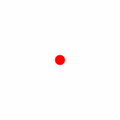

In [18]:
from pytamaro.de import *

hintergrund = rechteck(120, 120, weiss)

bilder = []
for durchmesser in range(10, 110, 10):
    kreis = ellipse(durchmesser, durchmesser, rot)
    bild = kombiniere(kreis, hintergrund)
    bilder.append(bild)

zeige_animation(bilder, 100)

Das Vorgehen ist immer dasselbe:

1. Eine leere Liste anlegen.
2. In einer Schleife jedes Einzelbild erzeugen und mit `.append()` anhängen.
3. Die fertige Liste an `zeige_animation()` übergeben.

Soll die Animation als Datei gespeichert werden, etwa um sie zu verschicken
oder auf einer Webseite zu verwenden, steht `speichere_animation()` zur
Verfügung. Sie funktioniert gleich, verlangt aber zusätzlich als erstes
Argument einen Dateinamen, der auf `.gif` enden muss:

```python
speichere_animation('kreis.gif', bilder, 100)
```

::: {.callout-warning title="Häufige Fehler bei Animationen"}

**Alle Einzelbilder müssen gleich gross sein.** Andernfalls erscheint die
Meldung *Alle Grafiken in der Liste müssen die gleiche Größe haben*. Ein
Daumenkino hat schliesslich auch lauter gleich grosse Seiten. Im Beispiel
oben sorgt der weisse Hintergrund dafür: Der Kreis wächst, das Bild nicht.

**Die Liste darf nicht leer sein.** Die Meldung *Die Liste der Grafiken darf
nicht leer sein* bedeutet meist, dass `.append()` in der Schleife vergessen
ging oder falsch eingerückt ist.

**`dauer` muss eine ganze Zahl sein.** `zeige_animation(bilder, 1000 / 12)`
führt zu einem Fehler, weil `/` immer eine Dezimalzahl ergibt. Richtig ist
`zeige_animation(bilder, 83)` oder `zeige_animation(bilder, 1000 // 12)`.

:::

## Anwendung: Ein animierter PacMan

Als erste Anwendung bauen wir einen PacMan, der an Ort bleibt und dabei den
Mund auf- und zuklappt.

![PacMan](pacman.png)

::: {.content-visible when-format="html"}

![PacMan animiert](pacman.gif)

:::

Wir gehen in zwei Schritten vor: Zuerst zeichnen wir einen einzelnen,
statischen PacMan. Anschliessend erzeugen wir daraus nach dem beschriebenen
Muster (leere Liste, Schleife, `.append()`) die Einzelbilder der Animation.

In [19]:
# Stellt sicher, dass alle deutschen PyTamaro-Funktionen zur Verfügung stehen
from pytamaro.de import *

### Schritt 1: Statischer PacMan

Der Körper des PacMan ist ein Kreissektor, dem ein Stück fehlt: der Mund.
Ein Sektor von 300° lässt eine Lücke von 60°, die mit `drehe()` so
ausgerichtet wird, dass der Mund nach rechts zeigt. Ein transparenter Kreis
als Hintergrund sorgt dafür, dass das Bild, bzw. dessen Bounding-Box, immer gleich gross ist, egal wie
weit der Mund offen steht. Das wird im zweiten Schritt wichtig, denn alle
Einzelbilder einer Animation müssen gleich gross sein. Zuletzt wird das Auge
mit einem transparenten Positionshalter an die richtige Stelle gesetzt.

In der folgenden Code-Zelle wird ein PacMan mit aufgesperrtem Mund
gezeichnet.

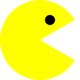

In [20]:
# TODO: Zeichne einen statischen PacMan
hintergrund = ellipse(80, 80, transparent)
pacman = kreis_sektor(40, 300, gelb)
pacman = drehe(30, pacman)
pacman = fixiere(mitte_links, pacman)
hintergrund = fixiere(mitte_links, hintergrund)
pacman = kombiniere(pacman, hintergrund)
auge = ellipse(10, 10, schwarz)
auge_positionshalter = rechteck(30, 20, transparent)
auge_positionshalter = fixiere(unten_links, auge_positionshalter)
auge = kombiniere(auge, auge_positionshalter)
auge = fixiere(oben_rechts, auge)
pacman = fixiere(oben_rechts, pacman)
pacman = kombiniere(auge, pacman)
zeige_grafik(pacman)
speichere_grafik('pacman.png', pacman)

### Schritt 2: Dynamischer PacMan

Für die Animation braucht es eine Liste von PacMan-Bildern mit
unterschiedlich weit geöffnetem Mund. Der Öffnungswinkel `winkel` soll von 0°
auf 60° anwachsen und danach wieder auf 0° zurückgehen. Genau dafür eignet
sich die Verbindung zweier `range` mit `+`, wie sie im Abschnitt
*Operationen mit Listen* gezeigt wurde. In jedem Schleifendurchlauf wird ein
Kreissektor von `360 - winkel` Grad gezeichnet und um `winkel / 2` gedreht,
damit der Mund symmetrisch nach rechts geöffnet ist. Alles, was sich von Bild
zu Bild nicht verändert (Hintergrund und Auge), wird einmal vor der Schleife
erstellt.

Die Liste enthält 120 Bilder. Bei der Standarddauer von 40 Millisekunden pro
Bild dauert ein Auf- und Zuklappen 4,8 Sekunden.

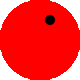

In [21]:
# TODO: Erstelle einen animierten PacMan
pacmen = []
hintergrund = ellipse(80, 80, transparent)
hintergrund = fixiere(mitte_links, hintergrund)

auge = ellipse(10, 10, schwarz)
auge_positionshalter = rechteck(30, 20, transparent)
auge_positionshalter = fixiere(unten_links, auge_positionshalter)
auge = kombiniere(auge, auge_positionshalter)
auge = fixiere(oben_rechts, auge)

winkel_liste = list(range(60)) + list(range(60, 0, -1))

for winkel in winkel_liste:

    pacman = kreis_sektor(40, 360-winkel, rot)
    pacman = drehe(winkel/2, pacman)
    pacman = fixiere(mitte_links, pacman)
    pacman = kombiniere(pacman, hintergrund)
    pacman = fixiere(oben_rechts, pacman)
    pacman = kombiniere(auge, pacman)
    pacmen.append(pacman)

    
zeige_animation(pacmen)
speichere_animation('pacman.gif', pacmen)

## Abschlussübung: Die Bahnhofsuhr der SBB

Zum Abschluss setzen wir alles Gelernte in einem grösseren Projekt ein.
Die Bahnhofsuhr der SBB ist eine Schweizer Design-Ikone.

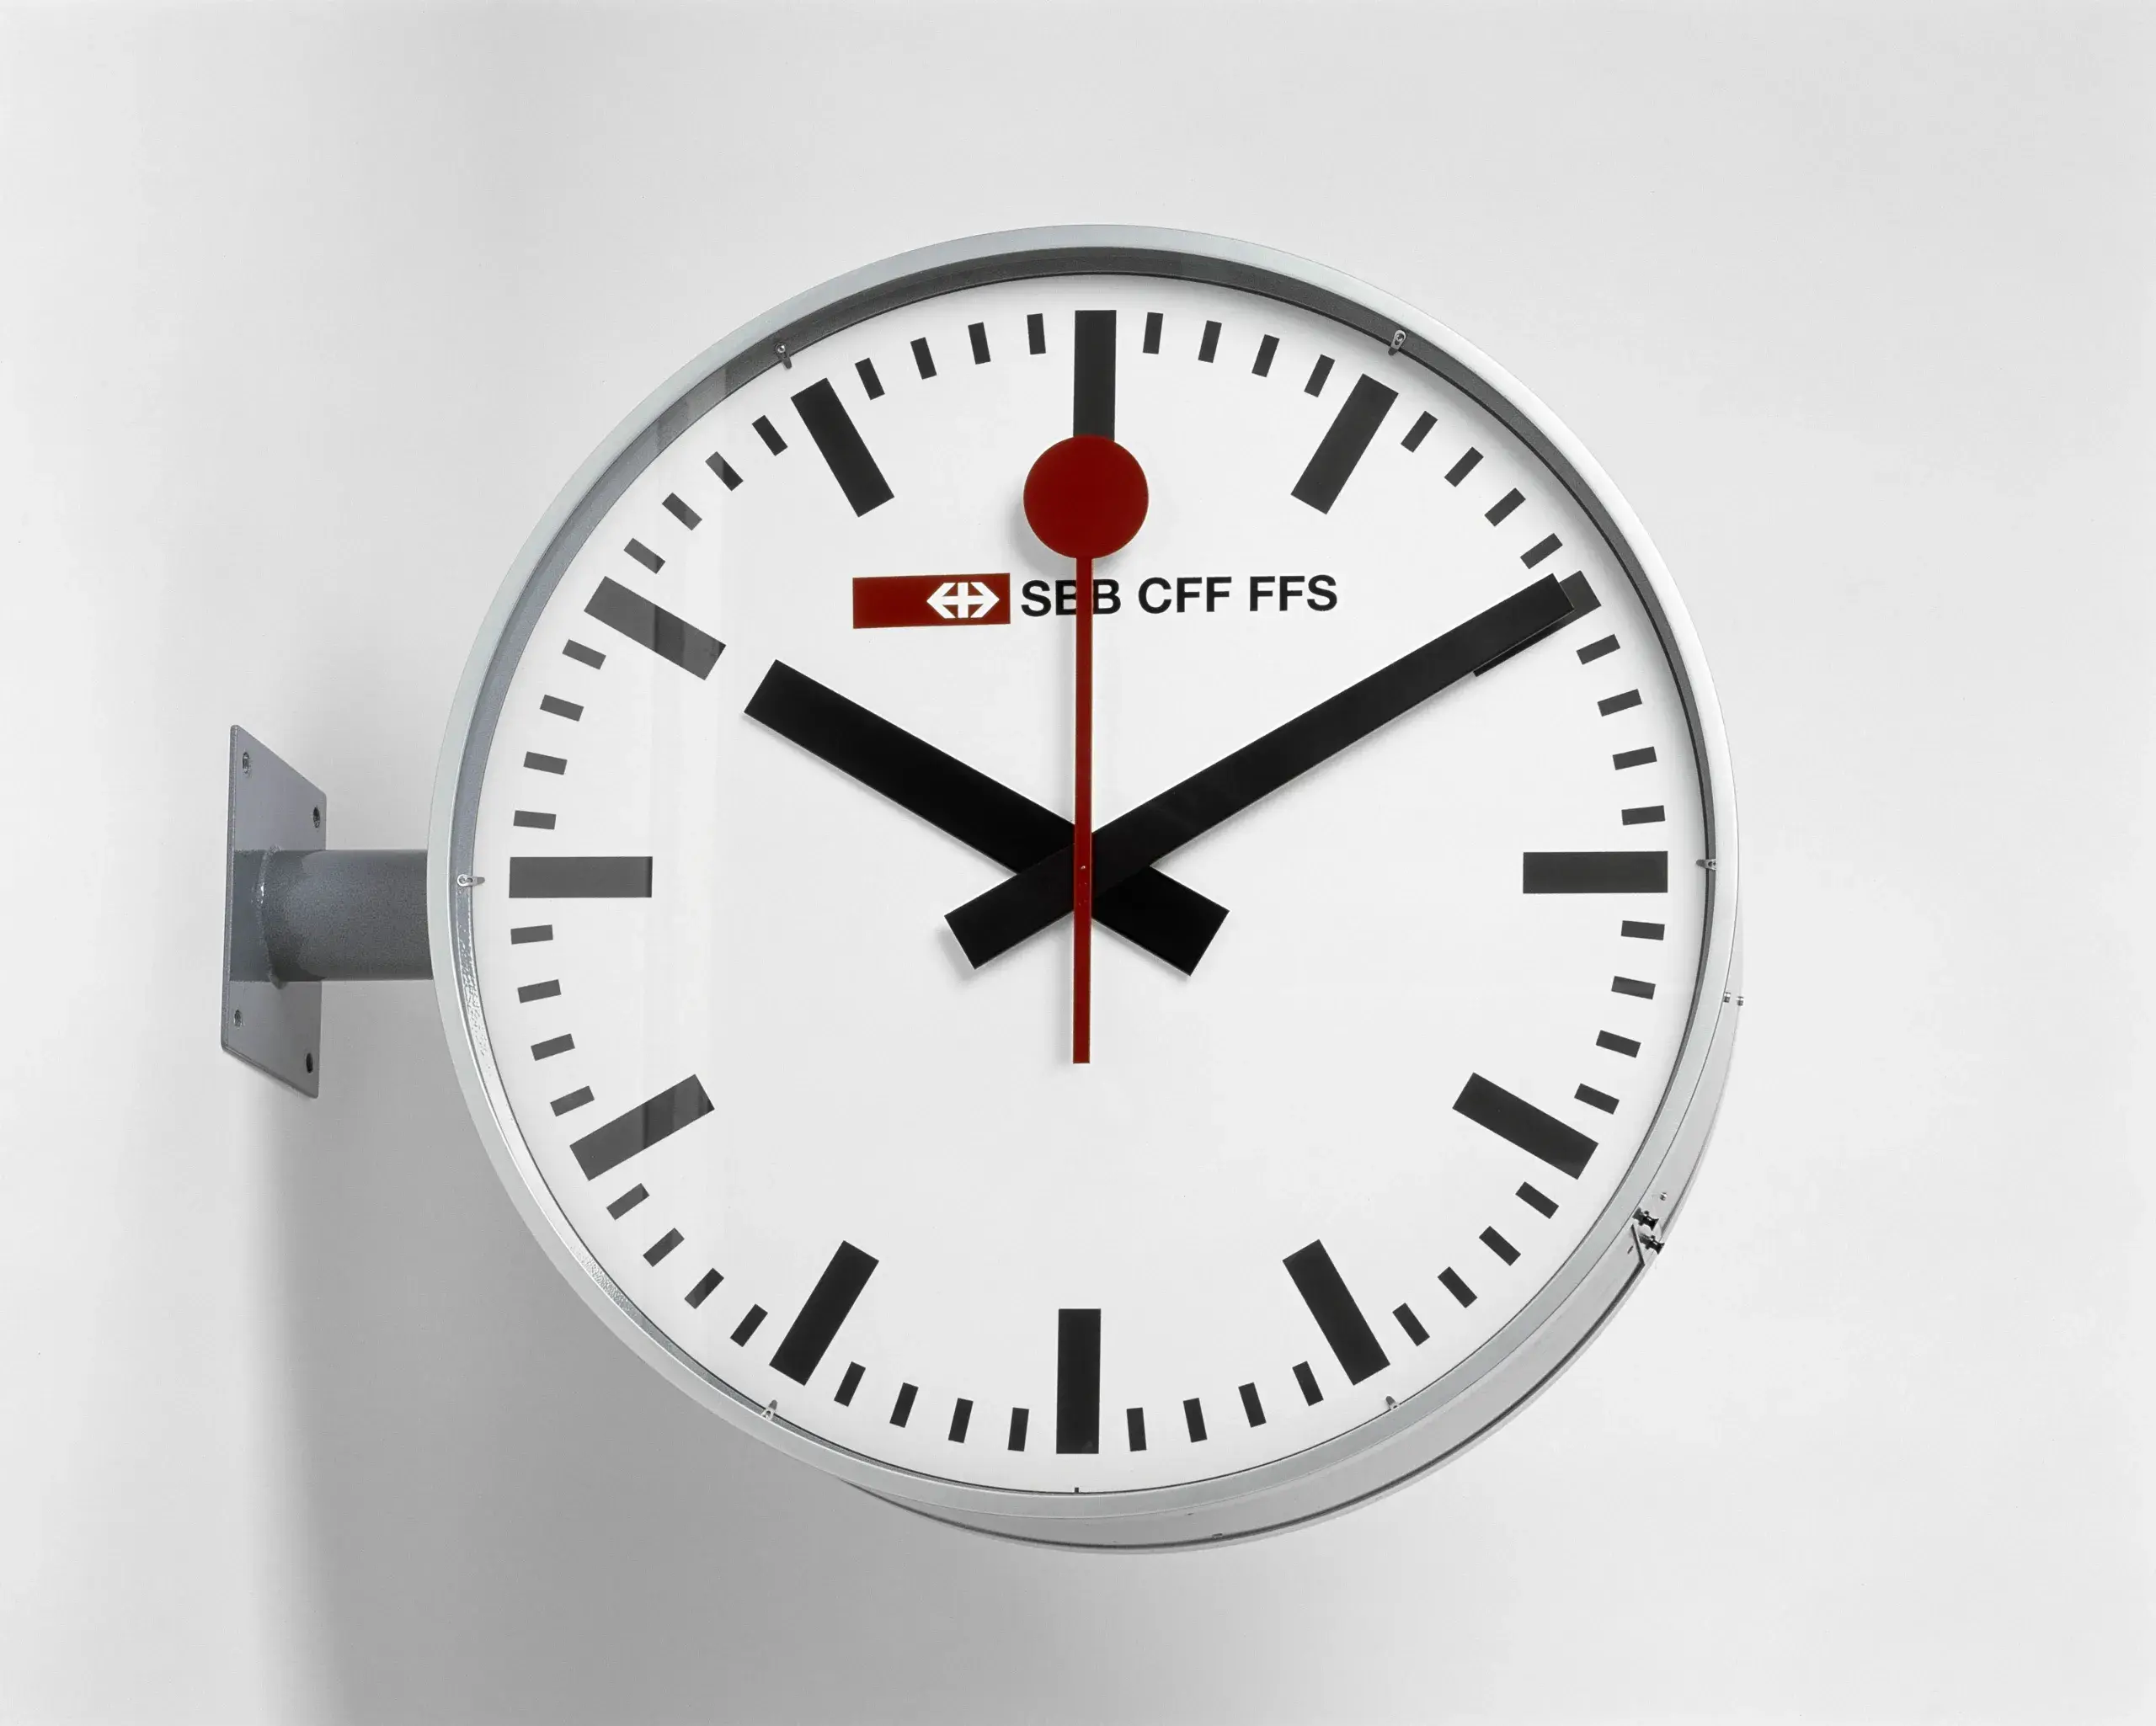

Entworfen wurde sie von [Hans Hilfiker (1901 -
1993)](https://www.emuseum.ch/people/275/hans-hilfiker). Die genauen
Dimensionen der einzelnen Merkmale der Uhr finden sich in der
untenstehenden Skizze. Alle Masse sind als Vielfache einer Einheit *a*
angegeben, die einem Hundertstel des Durchmessers entspricht. Wählen wir
*a* = 5, wird die Uhr 500 Pixel gross.

![Dimensionen der einzelnen Elemente der
Bahnhofsuhr.](bahnhofsuhr_transparent.png){width="50%"}

### Schritt 1: Stückliste

Die Uhr besteht aus den folgenden Elementen:

- Zifferblatt:
  - Hintergrund
  - Rahmen
  - Stundenstriche
  - Minutenstriche
- Zeiger:
  - Stundenzeiger
  - Minutenzeiger
  - Sekundenzeiger

Wir konstruieren die Elemente zuerst einzeln, setzen sie dann zu einer
statischen Uhr zusammen und bringen diese schliesslich mit Animationen zum
Laufen.

### Schritt 2: Konstruktion der einzelnen Elemente

#### Zifferblatt

Der Hintergrund besteht aus einem weissen Kreis mit 100*a* Durchmesser, der
auf einen minimal grösseren schwarzen Kreis gelegt wird. So entsteht der
Rahmen.

Für die Striche nutzen wir einen Trick: Jeder Strich wird über einen
transparenten Abstandhalter gesetzt, sodass Strich und Abstandhalter
zusammen genau den Radius von 48,5*a* abdecken. Wird diese Grafik in
`unten_mitte` fixiert, liegt der Fixierpunkt in der Mitte der Uhr, und
`drehe()` dreht den Strich um die Uhrmitte.

Hier kommen die Listen ins Spiel: Eine erste Schleife erzeugt die 12
Stundenstriche (alle 30°) bzw. die 60 Minutenstriche (alle 6°) und sammelt
sie in einer Liste. Eine zweite Schleife iteriert über diese Liste und fügt
jeden Strich zur Grafik hinzu. Ausgangspunkt ist dabei `leere_grafik()`, die
für Grafiken die Rolle übernimmt, die `[]` für Listen spielt.

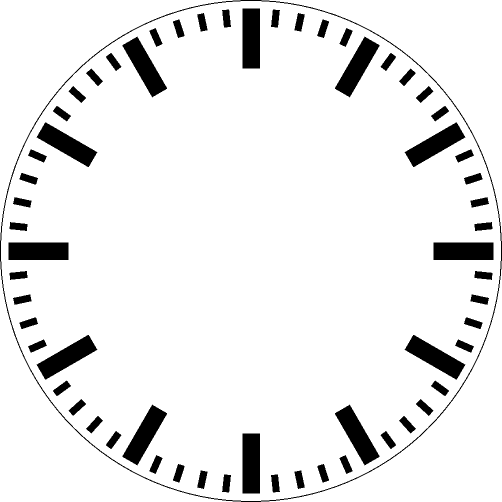

In [22]:
# TODO: Konstruktion Zifferblatt
a = 5
hintergrund = ellipse(100*a, 100*a, weiss)
rand = ellipse(100*a+2, 100*a+2, schwarz)
hintergrund = ueberlagere(hintergrund, rand)

stunde = rechteck(3.5*a, 12*a, schwarz)
abstandhalter_stunde = rechteck(3.5*a, (48.5-12)*a, transparent)
stunde = ueber(stunde, abstandhalter_stunde)
stunde = fixiere(unten_mitte, stunde)

minute = rechteck(1.4*a, 3.5*a, schwarz)
abstandhalter_minute = rechteck(1.4*a, (48.5-3.5)*a, transparent)
minute = ueber(minute, abstandhalter_minute)
minute = fixiere(unten_mitte, minute)

stunden = []
for i in range(0, 360, 30):
    strich = drehe(i, stunde)
    stunden.append(strich)
stundenstriche = leere_grafik()
for stunde in stunden:
    stundenstriche = kombiniere(stundenstriche, stunde)

minuten = []
for i in range(0, 360, 6):
    strich = drehe(i, minute)
    minuten.append(strich)
minutenstriche = leere_grafik()
for minute in minuten:
    minutenstriche = kombiniere(minutenstriche, minute)

zifferblatt = ueberlagere(stundenstriche, hintergrund)
zifferblatt = ueberlagere(minutenstriche, zifferblatt)
zeige_grafik(zifferblatt)
speichere_grafik('zifferblatt.png', zifferblatt)

#### Minuten- und Stundenzeiger

Die beiden Zeiger sind keine Rechtecke, sondern werden zur Spitze hin
schmaler. Gemäss Skizze ist der Minutenzeiger an der Spitze 3,6*a* und am
hinteren Ende 5,2*a* breit; vom Drehpunkt aus ragt er 46*a* nach vorn und
12*a* nach hinten. Der Stundenzeiger ist 5,2*a* bzw. 6,4*a* breit und ragt
32*a* nach vorn und 12*a* nach hinten.

Jeder Zeiger wird deshalb aus zwei Trapezen zusammengesetzt, die im
Drehpunkt aneinanderstossen. Zuerst wird berechnet, wie breit der Zeiger an
dieser Stelle ist. Jedes Trapez entsteht dann aus einem Rechteck, an das
links und rechts ein schmales rechtwinkliges Dreieck angesetzt wird. Das
vordere Trapez wird in `unten_mitte`, das hintere in `oben_mitte` fixiert.
Beim Kombinieren treffen sich die beiden Fixierpunkte, sodass der fertige
Zeiger im Drehpunkt fixiert ist.

In [23]:
# TODO: Konstruiere Minuten- und Stundenzeiger
# Minutenzeiger: Spitze 3.6a, Ende 5.2a, vorn 46a, hinten 12a
m_breite_mitte = 3.6*a + (5.2*a - 3.6*a) * 46 / 58   # Breite beim Drehpunkt

# vorderes Trapez (46a lang, oben 3.6a, unten m_breite_mitte)
d = (m_breite_mitte - 3.6*a) / 2
m_vorn = neben(drehe(90, dreieck(46*a, d, 90, schwarz)),
               neben(rechteck(3.6*a, 46*a, schwarz), dreieck(d, 46*a, 90, schwarz)))
m_vorn = fixiere(unten_mitte, m_vorn)

# hinteres Trapez (12a lang, oben m_breite_mitte, unten 5.2a)
d = (5.2*a - m_breite_mitte) / 2
m_hinten = neben(drehe(90, dreieck(12*a, d, 90, schwarz)),
                 neben(rechteck(m_breite_mitte, 12*a, schwarz), dreieck(d, 12*a, 90, schwarz)))
m_hinten = fixiere(oben_mitte, m_hinten)

minutenzeiger = kombiniere(m_vorn, m_hinten)

# Stundenzeiger: Spitze 5.2a, Ende 6.4a, vorn 32a, hinten 12a
s_breite_mitte = 5.2*a + (6.4*a - 5.2*a) * 32 / 44

d = (s_breite_mitte - 5.2*a) / 2
s_vorn = neben(drehe(90, dreieck(32*a, d, 90, schwarz)),
               neben(rechteck(5.2*a, 32*a, schwarz), dreieck(d, 32*a, 90, schwarz)))
s_vorn = fixiere(unten_mitte, s_vorn)

d = (6.4*a - s_breite_mitte) / 2
s_hinten = neben(drehe(90, dreieck(12*a, d, 90, schwarz)),
                 neben(rechteck(s_breite_mitte, 12*a, schwarz), dreieck(d, 12*a, 90, schwarz)))
s_hinten = fixiere(oben_mitte, s_hinten)

stundenzeiger = kombiniere(s_vorn, s_hinten)

#### Sekundenzeiger

Der Sekundenzeiger besteht aus einem schmalen roten Schaft mit einer runden
Scheibe am vorderen Ende. Weil er an die Signalkelle erinnert, mit der das
Bahnpersonal Züge zur Abfahrt freigibt, wird er oft *Kelle* genannt. Der
Schaft ist 1,4*a* breit und ragt 31,2*a* bis zum Mittelpunkt der Kelle nach
vorn und 16,5*a* nach hinten. Die Kelle hat einen Durchmesser von 10,5*a*.
Auch dieser Zeiger wird so zusammengesetzt, dass sein Fixierpunkt im
Drehpunkt liegt.

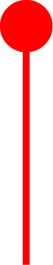

In [24]:
# TODO: Konstruiere Sekundenzeiger
spitze = ellipse(10.5*a, 10.5*a, rot)
schaft_vorn = rechteck(1.4*a, 31.2*a, rot)
schaft_vorn = fixiere(oben_mitte, schaft_vorn)
schaft_mit_spitze = kombiniere(spitze, schaft_vorn)
schaft_mit_spitze = fixiere(unten_mitte, schaft_mit_spitze)
schaft_hinten = rechteck(1.4*a, 16.5*a, rot)
schaft_hinten = fixiere(oben_mitte, schaft_hinten)
sekundenzeiger = kombiniere(schaft_mit_spitze, schaft_hinten)
zeige_grafik(sekundenzeiger)

### Schritt 3: Statische Kombination der einzelnen Elemente

Bevor sich etwas bewegt, prüfen wir, ob alle Teile zusammenpassen. Weil die
Zeiger im Drehpunkt und das Zifferblatt in seiner Mitte fixiert sind, genügt
`kombiniere()`, um sie deckungsgleich übereinanderzulegen. Die Reihenfolge
bestimmt, was vorne liegt: zuvorderst der Sekundenzeiger, dahinter Minuten-
und Stundenzeiger, zuhinterst das Zifferblatt.

Zu beachten ist die Drehrichtung: In PyTamaro dreht ein positiver Winkel
eine Grafik im Gegenuhrzeigersinn. Für eine Drehung im Uhrzeigersinn braucht
es deshalb negative Winkel. Im Beispiel zeigt die Uhr ungefähr zehn nach
zehn: Der Minutenzeiger wird um 60° im Uhrzeigersinn gedreht (`-60`), der
Stundenzeiger steht kurz nach der Zehn, also gut 50° links von der Zwölf
(`54`).

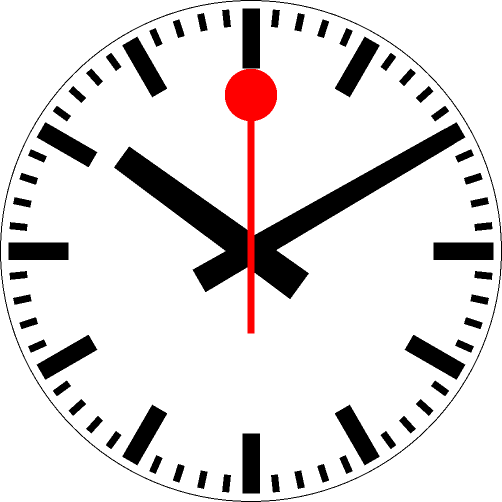

In [25]:
# TODO: Kombiniere die einzelnen Elemente zu einer Uhr (10:10)
zehn_uhr = drehe(54, stundenzeiger)
zehn_nach = drehe(-60, minutenzeiger)
uhrzeit = kombiniere(zehn_nach, zehn_uhr)
uhrzeit = kombiniere(sekundenzeiger, uhrzeit)
uhrzeit = kombiniere(uhrzeit, zifferblatt)
zeige_grafik(uhrzeit)

### Schritt 4: Die Uhr zum Laufen bringen

Die drei Zeiger der SBB-Uhr bewegen sich in unterschiedlichem Takt. Minuten-
und Stundenzeiger springen einmal pro Minute: Auf einen elektrischen Impuls
hin rückt der Minutenzeiger um 6° und der Stundenzeiger um 0,5° weiter. Der
Sekundenzeiger dagegen dreht sich in 58,5 Sekunden fliessend einmal um das
Zifferblatt und wartet dann 1,5 Sekunden auf der Zwölf auf den nächsten
Minutenimpuls.

Eine einzige Animation für alle drei Zeiger wäre deshalb riesig: Für eine
flüssige Bewegung braucht der Sekundenzeiger 20 Bilder pro Sekunde, über
einen Zwölfstundenumlauf ergäbe das über 860 000 Bilder. Wir erzeugen
deshalb zwei getrennte Animationen, eine für den Sekundenzeiger und eine für
Minuten- und Stundenzeiger, und legen sie erst im Browser über das
Zifferblatt.

Damit alle Bilder später deckungsgleich übereinanderliegen, wird jedes
Einzelbild mit einem transparenten Hintergrund von der Grösse des
Zifferblatts (100*a* × 100*a*) kombiniert. Gleichzeitig ist damit die
Bedingung erfüllt, dass alle Bilder einer Animation gleich gross sein
müssen.

#### Der Sekundenzeiger

Die Animation des Sekundenzeigers dauert genau eine Minute und besteht aus
1200 Bildern à 50 Millisekunden. Für die Umdrehung in 58,5 Sekunden sind
1170 Bilder nötig; von Bild zu Bild dreht sich der Zeiger um 360° / 1170
weiter. Für den Halt von 1,5 Sekunden wird anschliessend 30-mal dasselbe
Bild mit dem Zeiger auf der Zwölf angehängt.

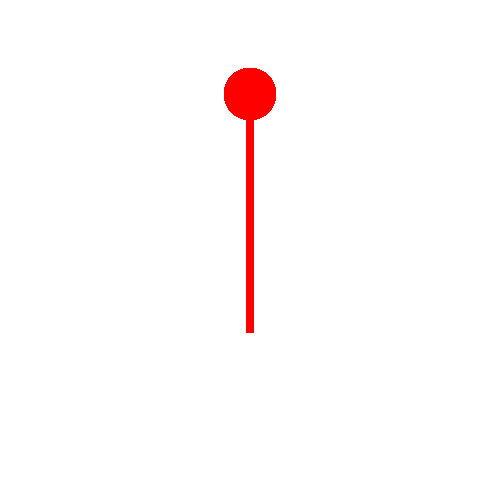

In [26]:
# TODO: Sekundenzeiger animieren
sekunden = []
hintergrund_transparent = ellipse(100*a, 100*a, transparent)

for i in range(1170):
    sekunde = drehe(-i * 360 / 1170, sekundenzeiger)
    sekunde = kombiniere(sekunde, hintergrund_transparent)
    sekunden.append(sekunde)

sekunden_stop = kombiniere(sekundenzeiger, hintergrund_transparent)
for i in range(30):
    sekunden.append(sekunden_stop)

zeige_animation(sekunden, dauer=50)
speichere_animation('sekunden.gif', sekunden, dauer=50)

#### Minuten- und Stundenzeiger

Für den Minutenzeiger allein ist die Aufgabe einfach: 60 Bilder, jedes um
weitere 6° gedreht und je eine Minute lang angezeigt. Ein Umlauf dauert also
eine Stunde. Python erlaubt in Zahlen den Unterstrich als Tausendertrennzeichen:
`60_000` ist dasselbe wie `60000`.

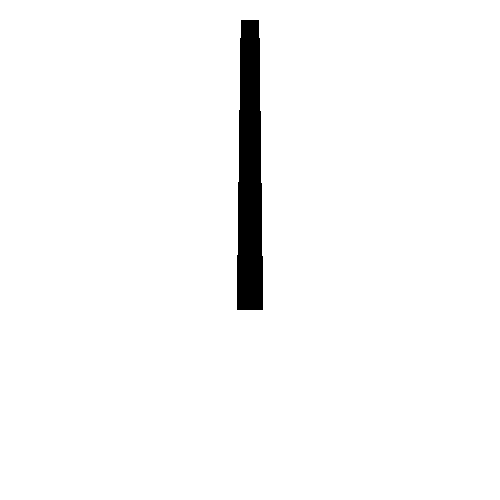

In [27]:
# TODO: Minutenzeiger animieren
minuten = []
for i in range(60):
    minute = drehe(-i * 6, minutenzeiger)
    minute = kombiniere(minute, hintergrund_transparent)
    minuten.append(minute)
    
zeige_animation(minuten, dauer=60_000)

Weil der Stundenzeiger im selben Moment springt wie der Minutenzeiger,
fassen wir beide in **einer** Animation zusammen. Für jede der 720 Minuten
eines Zwölfstundenumlaufs werden beide Zeiger auf ihre Position gedreht und
mit `kombiniere()` übereinandergelegt. Da bei beiden Zeigern die
Fixierposition im Drehpunkt liegt, treffen sie sich genau in der Mitte der
Uhr. Diese Animation wird nicht im Notebook abgespielt, sondern direkt als
`zeiger.gif` gespeichert.

In [28]:
# TODO: Minuten- und Stundenzeiger animieren
zeiger = []
for k in range(720):                        # 12 h × 60 min
    minute = drehe(-k * 6, minutenzeiger)
    stunde = drehe(-k * 0.5, stundenzeiger)
    bild = kombiniere(minute, stunde)       # Minutenzeiger vorne
    bild = kombiniere(bild, hintergrund_transparent)
    zeiger.append(bild)

speichere_animation("zeiger.gif", zeiger, dauer=60000)

#### Überlagerung mit HTML und CSS

Zusammengesetzt wird die Uhr erst im Browser. Das Zifferblatt (PNG) und die
beiden Animationen (GIF) haben einen transparenten Hintergrund und sind
gleich gross. Mit CSS legen wir sie wie Folien auf einem Hellraumprojektor
übereinander. Der folgende Code-Block kann in eine Markdown-Zelle des
Jupyter Notebooks eingefügt werden; die drei Bilddateien müssen im selben
Ordner wie das Notebook liegen:

```html
<div style="position:relative; width:100%; max-width:500px">
  <img src="zifferblatt.png" style="width:100%">
  <img src="zeiger.gif"      style="position:absolute; top:0; left:0; width:100%">
  <img src="sekunden.gif"    style="position:absolute; top:0; left:0; width:100%">
</div>
```

- `position:relative` macht den äusseren `div` zum Bezugsrahmen.
- `position:absolute; top:0; left:0` setzt die beiden GIFs in die linke
  obere Ecke dieses Rahmens, also genau über das Zifferblatt.
- `width:100%` macht alle Bilder so breit wie den Rahmen, `max-width` legt
  die Grösse der Uhr fest.
- Die **Reihenfolge im HTML** bestimmt die Stapelung: Was später steht,
  liegt weiter vorne. Der Sekundenzeiger mit der roten Kelle steht deshalb
  zuletzt.

Jede Animation läuft im Browser in ihrem eigenen Takt. So entsteht eine Uhr
mit drei unterschiedlich schnellen Zeigern, ohne dass alle Bilder in einer
einzigen Datei stecken müssen. Ein Nachteil bleibt: Die Animationen sind
nicht miteinander gekoppelt, sodass der Minutensprung nicht immer exakt mit
dem Halt der Kelle zusammenfällt.

In der nächsten Zelle ist genau dieser Block eingefügt. Sie zeigt die
fertige Uhr.

<div style="position:relative; width:100%; max-width:500px">
  <img src="zifferblatt.png" style="width:100%">
  <img src="zeiger.gif"      style="position:absolute; top:0; left:0; width:100%">
  <img src="sekunden.gif"    style="position:absolute; top:0; left:0; width:100%">
</div>

## Rückblick

Listen sind in diesem Kapitel in drei Rollen aufgetreten: als Sammlung von
Werten, die mit Funktionen, Operatoren und Methoden bearbeitet wird; als
Folge von Grafiken, die PyTamaro als Daumenkino abspielt; und als
Zwischenablage, in der zuerst alle Teile erzeugt und danach zu einer Grafik
zusammengesetzt werden, wie bei den Strichen des Zifferblatts. Das Muster
ist dabei immer dasselbe: eine leere Liste anlegen, sie in einer Schleife
mit `.append()` füllen und die fertige Liste weiterverwenden.